In [1]:
import argparse
import scanpy as sc
import scimap as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import anndata as ad
from sklearn.decomposition import NMF



Running SCIMAP  2.3.5


/root/miniconda3/envs/scimap/lib/python3.10/site-packages/mpl_scatter_density/__init__.py:4: UserWarning:

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.



In [2]:

adata = sc.read("./IWD_plaque.h5ad")
adata.obsm['spatial'] = adata.obsm['X_spatial']

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [4]:
adata

AnnData object with n_obs × n_vars = 9988 × 4495
    obs: 'orig.ident', 'nCount_Xenium', 'nFeature_Xenium', 'nucleus_area', 'cell_area', 'nc_ratio', 'Cell_Anno', 'group', 'Type', 'nCount_SCT', 'nFeature_SCT', 'niche', 'domain', 'plaque', 'barcode'
    uns: 'log1p'
    obsm: 'X_pca', 'X_spatial', 'X_umap', 'spatial'

In [5]:
adata.obs['batch']=1
adata.obs['X_centroid'] = adata.obsm['spatial'][:, 0]  
adata.obs['Y_centroid'] = adata.obsm['spatial'][:, 1]  
adata= sm.tl.spatial_count(adata, phenotype='Cell_Anno', 
                            method='radius', radius=100, label='spatial_count',imageid='batch')

Identifying neighbours within 100 pixels of every cell


In [8]:

adata = ad.AnnData(X=adata.uns['spatial_count'],obs = adata.obs,uns = adata.uns)

adata.var.index = adata.uns['spatial_count'].columns

adata.uns['spatial_count'] = adata.uns['spatial_count'].loc[adata.obs.index,:]

nmf = NMF(n_components=5, init='random', random_state=42)

#nmf_features = nmf.fit_transform(adata.uns['spatial_count'])

In [7]:


adata.obsm['NMF'] = nmf_features

sc.pp.neighbors(adata, use_rep='NMF')

sc.tl.leiden(adata, resolution=0.05, key_added='neighborhood_clusters')




/tmp/ipykernel_651/88143997.py:5: FutureWarning:

In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.



In [18]:
adata

In [17]:
adata1 = adata[adata.obs['Type'] == 'CWD']######
adata1 = adata1[adata1.obs['Cell_Anno'] == 'FMC_2']

In [18]:
###
# 
def calculate_gene_percentage(adata):
    # 
    if hasattr(adata.X, 'toarray'):
        # 
        gene_sums = np.array(adata.X.sum(axis=0)).flatten()
    else:
        # 
        gene_sums = adata.X.sum(axis=0)
    
    # 
    total_expression = gene_sums.sum()
    
    # 
    gene_percentages = (gene_sums / total_expression) * 100
    
    #
    result_df = pd.DataFrame({
        'gene': adata.var_names,
        'total_expression': gene_sums,
        'percentage': gene_percentages
    })
    
    # 
    result_df = result_df.sort_values('percentage', ascending=False)
    
    return result_df

# 
gene_percentage_df = calculate_gene_percentage(adata1)
print(gene_percentage_df)

        gene  total_expression  percentage
6      FMC_4         30.630321   29.171734
10    Inf EC         16.688092   15.893421
16      vSMC         16.677205   15.883052
12      LAMs         16.180776   15.410263
4      FMC_2         14.469443   13.780422
11   Inf Mac          4.509489    4.294751
3      FMC_1          1.927682    1.835887
14   Res Mac          1.153212    1.098297
5      FMC_3          0.538146    0.512520
9      FMC_7          0.519971    0.495210
15    T cell          0.457009    0.435247
7      FMC_5          0.426826    0.406501
1     B cell          0.230348    0.219379
2   EndMT EC          0.225114    0.214394
0   Angio EC          0.172432    0.164221
8      FMC_6          0.108497    0.103331
13    Res EC          0.085438    0.081369


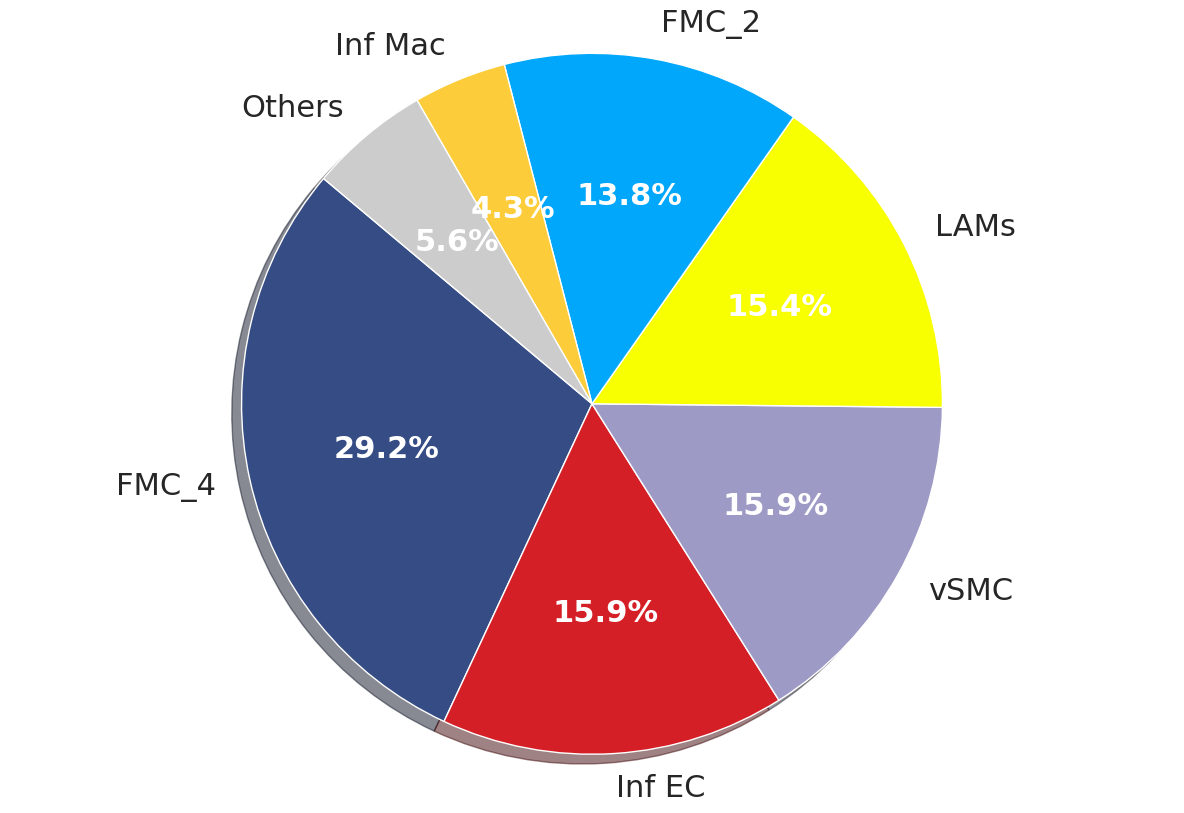

Total number of genes: 17
Number of major genes displayed: 6
Number of merged other genes: 11
Total share of other genes: 5.57%


In [19]:

# 
color_mapping =   {
    'Inf EC': '#d51f26',
    'EndMT EC': "#f3758a",
    'Angio EC': "#ff87bbff",
    'Res EC': "#fbaeb5",
    'T cell': '#0F7240',
    'B cell': '#B7B663',
    'Res Mac': '#d5a339',
    'LAMs': '#f8ff00',
    'Inf Mac': '#fccc3a',
    'vSMC': '#9d9ac6',
    'FMC_1': '#bbe379','FMC_2': '#00a7fa','FMC_3': '#b9e6fb',
    'FMC_4': '#354c85','FMC_5': '#b1ddcc','FMC_6': '#C9E1AF','FMC_7': '#31aaaa',
    
}



# 
labels = gene_percentage_df['gene'].tolist()
sizes = gene_percentage_df['percentage'].tolist()

# 
colors = [color_mapping.get(gene, '#cccccc') for gene in labels]  # 

# 
threshold = 2.0  # 

# 
main_genes = gene_percentage_df[gene_percentage_df['percentage'] >= threshold]
other_genes = gene_percentage_df[gene_percentage_df['percentage'] < threshold]

# 
main_labels = main_genes['gene'].tolist()
main_sizes = main_genes['percentage'].tolist()
main_colors = [color_mapping.get(gene, '#cccccc') for gene in main_labels]

# 
if len(other_genes) > 0:
    other_percentage = other_genes['percentage'].sum()
    main_labels.append(f'Others')
    main_sizes.append(other_percentage)
    main_colors.append('#cccccc')  # 

# 
plt.figure(figsize=(12, 8))
wedges, texts, autotexts = plt.pie(
    main_sizes,
    labels=main_labels,
    colors=main_colors,
    autopct='%1.1f%%',
    startangle=140,
    shadow=True,
    textprops={'fontsize': 22}
)

# 
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.axis('equal')
plt.tight_layout()

# 
plt.savefig('./Cwd_FMC2_pie_chart.png',#######
            dpi=500, bbox_inches='tight', facecolor='white')
plt.show()


In [8]:
# 
results_fdr = compare_neighborhood_expression_corrected(
    adata, 
    group_col='Hip', 
    group_a='niche_2',    #
    group_b='niche_3',
    correction_method='fdr_bh',  #
    pval_threshold=0.01,        # 
    min_expr_cells=10           # 
)


In [52]:
#
adata2 = adata

adata2= sm.tl.spatial_count(adata2, phenotype='Cell_Anno', # cell
                            method='radius', radius=50, label='spatial_count',imageid='batch')
adata2 = ad.AnnData(X=adata2.uns['spatial_count'],obs = adata2.obs,uns = adata2.uns)

adata2.var.index = adata2.uns['spatial_count'].columns

adata2.uns['spatial_count'] = adata2.uns['spatial_count'].loc[adata.obs.index,:]


Identifying neighbours within 50 pixels of every cell


In [68]:
def compare_neighborhood_expression_corrected(adata, group_col, group_a, group_b, 
                                            neighborhood_matrix_key='spatial_count',
                                            min_cells=10, pval_threshold=0.05,
                                            correction_method='fdr_bh', min_expr_cells=5):
  
    
    # 
    if group_col not in adata.obs.columns:
        raise ValueError(f"column '{group_col}' does not exist in adata.obs")
    
    if neighborhood_matrix_key not in adata.uns:
        raise ValueError(f"neighborhood matrix '{neighborhood_matrix_key}' does not exist in adata.uns")
    
    # 
    adata.obs[group_col] = adata.obs[group_col].astype('category')
    group_a_idx = adata.obs[adata.obs[group_col] == group_a].index
    group_b_idx = adata.obs[adata.obs[group_col] == group_b].index
    
    if len(group_a_idx) < min_cells or len(group_b_idx) < min_cells:
        raise ValueError(f"at least one group has fewer than {min_cells} cells")
    
    # 
    neighborhood_matrix = adata.uns[neighborhood_matrix_key]
    
    # 
    neighborhood_a = neighborhood_matrix.loc[group_a_idx].mean(axis=0)
    neighborhood_b = neighborhood_matrix.loc[group_b_idx].mean(axis=0)
    neighborhood_diff = neighborhood_a - neighborhood_b
    
    # 
    expr_a = adata[group_a_idx, :].X
    expr_b = adata[group_b_idx, :].X
    
    if hasattr(expr_a, 'toarray'):
        expr_a = expr_a.toarray()
        expr_b = expr_b.toarray()
    
    gene_diff = expr_a.mean(axis=0) - expr_b.mean(axis=0)
    
    # 
    from statsmodels.stats.multitest import multipletests
    
    p_values = []
    valid_genes = []
    
    for i, gene in enumerate(adata.var_names):
        expr_a_gene = expr_a[:, i]
        expr_b_gene = expr_b[:, i]
        
        # 
        n_expr_a = np.sum(expr_a_gene > 0)
        n_expr_b = np.sum(expr_b_gene > 0)
        
        # 
        if n_expr_a < min_expr_cells and n_expr_b < min_expr_cells:
            p_values.append(1.0)
            valid_genes.append(False)
            continue
        
        valid_genes.append(True)
        
        try:
            # 
            u_stat, p_val = stats.mannwhitneyu(expr_a_gene, expr_b_gene, alternative='two-sided')
            p_values.append(p_val)
        except:
            p_values.append(1.0)
    
    # 
    valid_p_values = [p for i, p in enumerate(p_values) if valid_genes[i]]
    
    if len(valid_p_values) > 0:
        # 
        if correction_method == 'fdr_bh':
            # 
            reject, adj_p, _, _ = multipletests(valid_p_values, alpha=pval_threshold, method='fdr_bh')
        elif correction_method == 'bonferroni':
            # 
            reject, adj_p, _, _ = multipletests(valid_p_values, alpha=pval_threshold, method='bonferroni')
        elif correction_method == 'fdr_by':
            # 
            reject, adj_p, _, _ = multipletests(valid_p_values, alpha=pval_threshold, method='fdr_by')
        else:
            raise ValueError("unsupported correction method")
        
        # 
        full_adj_p = np.ones(len(p_values))
        valid_idx = 0
        for i, is_valid in enumerate(valid_genes):
            if is_valid:
                full_adj_p[i] = adj_p[valid_idx]
                valid_idx += 1
    else:
        full_adj_p = np.ones(len(p_values))
    
    # 7. 
    result_df = pd.DataFrame({
        'gene': adata.var_names,
        f'{group_a}_vs_{group_b}_log2FC': gene_diff,
        'abs_log2FC': abs(gene_diff),
        'p_value': p_values,
        'adj_p_value': full_adj_p,
        'significant': full_adj_p < pval_threshold,
        'valid_gene': valid_genes
    })
    
    # 8. 
    result_df['mean_expr_a'] = expr_a.mean(axis=0)
    result_df['mean_expr_b'] = expr_b.mean(axis=0)
    result_df['expr_ratio'] = result_df['mean_expr_a'] / (result_df['mean_expr_b'] + 1e-6)
 
    results = {
        'group_a': group_a,
        'group_b': group_b,
        'correction_method': correction_method,
        'pval_threshold': pval_threshold,
        'neighborhood_diff': neighborhood_diff,
        'expression_results': result_df,
        'significant_genes': result_df[result_df['significant']],
        'valid_genes_count': sum(valid_genes),
        'significant_count': sum(result_df['significant'])
    }
    
    return results




def compare_neighborhood_cell(adata, niche_col='Hip', group_a='niche_2', group_b='niche_3',
                              cell_anno_col='Cell_Anno', target_celltype='EC',
                              colors=['#FF9AA2', '#B5EAD7'],  # 
                              top_genes=20, figsize=(20, 15), save_path=None,
                              font_size=14, title_size=16):
  
    
    # 
    plt.style.use('default')
    sns.set_style("white")  # 
    
    # 2. 
    ec_cells = adata.obs[adata.obs[cell_anno_col] == target_celltype].index
    print(f"Found {len(ec_cells)} {target_celltype} cells")
    
    if len(ec_cells) == 0:
        raise ValueError(f"No {target_celltype} cells found")
    
    # 3. 
    group_a_ec = adata.obs[(adata.obs[cell_anno_col] == target_celltype) & 
                          (adata.obs[niche_col] == group_a)].index
    group_b_ec = adata.obs[(adata.obs[cell_anno_col] == target_celltype) & 
                          (adata.obs[niche_col] == group_b)].index
    
    print(f"{group_a} group {target_celltype} cell count: {len(group_a_ec)}")
    print(f"{group_b} group {target_celltype} cell count: {len(group_b_ec)}")
    
    if len(group_a_ec) == 0 or len(group_b_ec) == 0:
        raise ValueError(f"at least one group has 0 {target_celltype} cells")
    
    # 4. 
    expr_matrix = adata.X
    if hasattr(expr_matrix, 'toarray'):
        expr_matrix = expr_matrix.toarray()
    
    expr_df = pd.DataFrame(expr_matrix, index=adata.obs.index, columns=adata.var_names)
    
    # 5. 
    genes = adata.var_names
    p_values = {}
    mean_diff = {}
    effect_size = {}
    
    for gene in genes:
        expr_a = expr_df.loc[group_a_ec, gene]
        expr_b = expr_df.loc[group_b_ec, gene]
        
        # 
        if np.sum(expr_a > 0) < 5 or np.sum(expr_b > 0) < 5:
            p_values[gene] = 1.0
            mean_diff[gene] = 0
            effect_size[gene] = 0
            continue
        
        # 
        mean_a = expr_a.mean()
        mean_b = expr_b.mean()
        mean_diff[gene] = mean_a - mean_b
        
        try:
            t_stat, p_val = stats.ttest_ind(expr_a, expr_b, equal_var=False)
            p_values[gene] = p_val
            
            pooled_std = np.sqrt((expr_a.std()**2 + expr_b.std()**2) / 2)
            if pooled_std > 0:
                effect_size[gene] = (mean_a - mean_b) / pooled_std
            else:
                effect_size[gene] = 0
        except:
            p_val = 1.0
            p_values[gene] = p_val
            effect_size[gene] = 0
    
    # 6. 
    result_df = pd.DataFrame({
        'gene': genes,
        f'{group_a}_mean': [expr_df.loc[group_a_ec, gene].mean() for gene in genes],
        f'{group_b}_mean': [expr_df.loc[group_b_ec, gene].mean() for gene in genes],
        'mean_difference': [mean_diff[gene] for gene in genes],
        'p_value': [p_values[gene] for gene in genes],
        'effect_size': [effect_size[gene] for gene in genes]
    })
    
    result_df_sorted = result_df.sort_values('p_value')
    
    # 7. 
    top_genes_list = result_df_sorted.head(top_genes)['gene'].tolist()
    
    n_cols = 4
    n_rows = (len(top_genes_list) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    axes = axes.flatten() if n_rows > 1 else [axes]
    
    for i, gene in enumerate(top_genes_list):
        if i >= len(axes):
            break
            
        # 
        expr_a = expr_df.loc[group_a_ec, gene]
        expr_b = expr_df.loc[group_b_ec, gene]
        p_val = p_values[gene]
        effect = effect_size[gene]
        
        # 
        data_to_plot = pd.DataFrame({
            'Group': [group_a] * len(expr_a) + [group_b] * len(expr_b),
            'Expression': np.concatenate([expr_a, expr_b])
        })
        
        # 
        sns.boxplot(data=data_to_plot, x='Group', y='Expression', 
                   palette=colors, width=0.6, ax=axes[i], 
                   fliersize=2, linewidth=1.5)
        
        # 
        sns.violinplot(data=data_to_plot, x='Group', y='Expression', 
                      palette=colors, alpha=0.3, ax=axes[i], cut=0)
        
        # 
        sns.stripplot(data=data_to_plot, x='Group', y='Expression', 
                     palette=colors, alpha=0.6, size=3, jitter=0.2, ax=axes[i])
        
        # 
        if p_val < 0.001:
            p_text = '✨***✨'
            text_color = '#FF6B9D'
        elif p_val < 0.01:
            p_text = '✨**✨'
            text_color = '#FF9F7F'
        elif p_val < 0.05:
            p_text = '✨*✨'
            text_color = '#FFD93D'
        else:
            p_text = '🌸ns🌸'
            text_color = '#A0E7E5'
        
        # 
        y_max = max(expr_a.max(), expr_b.max())
        axes[i].text(0.5, y_max * 0.95, p_text, ha='center', va='bottom', 
                    fontsize=font_size+2, fontweight='bold', color=text_color,
                    bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.9))
        
        # 
        axes[i].set_title(f'{gene}\n(p={p_val:.4f}, d={effect:.2f})', 
                         fontsize=title_size, fontweight='bold', pad=12)
        axes[i].set_xlabel('', fontsize=font_size)
        axes[i].set_ylabel('Neighborhood cell', fontsize=font_size)
        
        # 
        axes[i].tick_params(axis='both', which='major', labelsize=font_size-2)
        
        # 
        axes[i].grid(False)
        axes[i].spines['top'].set_visible(True)
        axes[i].spines['right'].set_visible(True)
        axes[i].spines['bottom'].set_visible(True)
        axes[i].spines['left'].set_visible(True)
    
    # 
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)
    
    # 
    plt.suptitle(f'🎀 Gene expression difference of {target_celltype} cells in {group_a} vs {group_b} 🎀', 
                fontsize=title_size+4, fontweight='bold', y=1.02, color='#FF6B9D')
    plt.tight_layout()
    
    # 8. 
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300, facecolor='white')
        print(f"✨ Figure saved to: {save_path}")
    
    # 9. 
    results = {
        'figure': fig,
        'all_statistics': result_df,
        'top_statistics': result_df_sorted.head(top_genes),
        'p_values': p_values,
        'mean_diff': mean_diff,
        'effect_sizes': effect_size
    }
    
    return results